# TP1 PROCESAMIENTO DEL HABLA: webscrapping

**Crea una copia de este notebook en tu google colab**

**Renombra el notebook con el siguiente formato APELLIDO_NOMBRE_PH_TP1.ipynb**

**[Nicolás Druetta]**


* Resolver las consignas comentando el código fuente, indicando desde dónde fue extraido o generado.

* Explicar y justificar cada paso realizado usando los bloques de texto.

* Publique enlace público a su notebook en google colab y también enlace a su repositorio github de la materia.


## EJERCICIO CONSIGNA

* Cree una nube de palabras de un texto en español.

* Dicho texto puede ser descargado de Internet (webscrapping) o extraído del dataset de alguna librería.

* Puede usar cualquier libreria o herramienta para obtener el texto de su interés.

* En este notebook explica el paso a paso del proceso.



## 1- Webscrapping

Extrae un texto de Internet de una sóla página web usando alguna de las técnicas de webscrapping vistas en clase. Busca el discurso de alguna persona quien te inspire o haya dado una charla motivadora.

No puedes repetir ni usar ni el mismo texto ni la misma web que otra persona quien ya entregó en el foro.

Abajo añade los bloques de código y texto necesarios. Explica paso a paso como descargaste el texto de tu interés.


> Para este trabajo elijo una conferencia de Santiago Bilinkis sobre inteligencia artificial y el futuro de la humanidad, realizada en el evento Roca Futuro 2026. El texto se encuentra disponible en el sitio web Río Negro al Día. Para extraer el contenido voy a realizar web scraping sobre la página utilizando las herramientas aprendidas en clase.

### 1.1 Instalo las librerías que voy a utilizar.

In [51]:
# Instalo las librerías que voy a utilizar para realizar el webscrapping
# ! pip install requests beautifulsoup4 html5lib wordcloud

### 1.2 Importo las librerías que voy a utilizar.

In [52]:
# Importo las librerías que voy a utilizar
import matplotlib.pyplot as plt
import nltk
import pandas as pd
import re
import requests
import string

from bs4 import BeautifulSoup
from collections import Counter
from google.colab import data_table
from IPython.display import HTML
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from wordcloud import WordCloud

### 1.3 Descargo lo que necesito de NLTK.

In [53]:
# Descargo el tokenizador de NLTK
nltk.download("punkt")
nltk.download("punkt_tab")

# Descargo las stop words de NLTK
nltk.download("stopwords")

# Obtengo las stop words en español
stopwords_es = set(stopwords.words("spanish"))

# Muestro las primeras stop words
print(list(stopwords_es)[:7])

['sentid', 'están', 'mi', 'hasta', 'tienes', 'tengas', 'hayamos']


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### 1.4 Defino un estilo CSS mínimo para las DataTables.

In [95]:
# Defino el estilo de las DataTables
style_datatables = """
<style>
  .google-visualization-table-table {
    border-top: 1px solid #c4c7c5;
    font-size: 15px !important;
  }

  .google-visualization-table-page-numbers {
    float: left !important;
  }

  .interactive-table-header,
  .num-per-page {
    display: none !important;
  }
</style>
"""

### 1.5 Trabajo inicial con el texto.

#### 1.5.1 Request HTTP.

In [55]:
# Guardo la URL de la página que contiene el texto de La metamorfosis
url = "https://rionegroaldia.com/2026/09/04/santiago-bilinkis-inteligencia-artificial-roca-futuro/"

# Realizo la solicitud HTTP
respuesta = requests.get(url)

# Muestro la respuesta
respuesta

<Response [200]>

#### 1.5.2 Muestro el HTML del sitio.

In [56]:
# Analizo el contenido HTML de la página
sopa = BeautifulSoup(respuesta.text, "html.parser")

# Muestro los primeros caracteres del HTML
print(str(sopa)[:500])

<!DOCTYPE html >

<html lang="es" prefix="og: http://ogp.me/ns# article: http://ogp.me/ns/article#">
<head>
<meta charset="utf-8"/>
<title>Santiago Bilinkis expuso sobre IA en Diario Río Negro | Roca Futuro</title>
<meta content="width=device-width, initial-scale=1.0" name="viewport"/>
<link href="https://rionegroaldia.com/xmlrpc.php" rel="pingback"/>
<meta content="index, follow, max-image-preview:large, max-snippet:-1, max-video-preview:-1" name="robots">
<!-- This site is optimized with the Y


#### 1.5.3 Muestro el HTML del texto.

In [57]:
# Busco el contenedor principal de la nota
div_container = sopa.find(class_="td-post-content")

# Busco el contenido dentro del contenedor
div_content = div_container.find("div", class_="tdb-block-inner td-fix-index")

# Muestro los primeros caracteres del div con el HTML formateado
print(div_content.prettify()[:500])

<div class="tdb-block-inner td-fix-index">
 <p>
  <strong>
   En el marco del ciclo «Roca Futuro», el empresario y tecnólogo argentino Santiago Bilinkis brindó una conferencia sobre inteligencia artificial en el auditorio de Diario Río Negro, donde abordó las claves para interactuar con estas herramientas, el impacto de la «IA agéntica» y los riesgos asociados a su uso.
  </strong>
 </p>
 <p>
  En el marco del ciclo de charlas «Roca Futuro», el empresario y tecnólogo argentino Santiago Bilinkis 


#### 1.5.4 Extraigo el texto.

In [58]:
# Obtengo el texto de la conferencia
texto = div_content.get_text()

# Muestro los primeros caracteres del texto
print(texto[:500])

En el marco del ciclo «Roca Futuro», el empresario y tecnólogo argentino Santiago Bilinkis brindó una conferencia sobre inteligencia artificial en el auditorio de Diario Río Negro, donde abordó las claves para interactuar con estas herramientas, el impacto de la «IA agéntica» y los riesgos asociados a su uso.
En el marco del ciclo de charlas «Roca Futuro», el empresario y tecnólogo argentino Santiago Bilinkis brindó una conferencia sobre Inteligencia Artificial (IA) en el auditorio de Diario Río


#### 1.5.5 Primera nube de palabras.

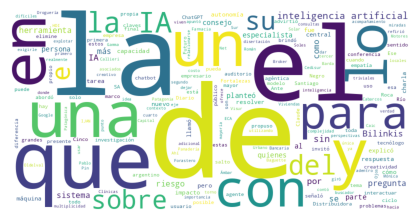

In [106]:
# Creo un objeto WordCloud
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(texto)

# Muestro la explicación de la nube de palabras
display(HTML("""
<p style="font-size: 16px;">
<b>Primera nube:</b> tamaño de la palabra = cantidad de apariciones.
</p>
<br />
"""))

# Muestro la imagen generada
plt.figure(figsize=(4, 4), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()

## 2- Preprocesamiento

### 2.1 Muestro las stop words que tiene mi texto.

In [80]:
# Separo mi texto en palabras
palabras = texto.lower().split()

# Busco las stop words que aparecen en mi texto
stopwords_texto = [palabra for palabra in palabras if palabra in stopwords_es]

# Cuento cuántas veces aparece cada stop word
conteo_stopwords = Counter(stopwords_texto)

# Creo una tabla con las stop words y sus cantidades
tabla_stopwords = pd.DataFrame(
    conteo_stopwords.most_common(),
    columns=["Stop Word", "Cantidad"]
)

# Aplico el estilo de la tabla
display(HTML(style_datatables))

# Muestro la tabla paginada con DataTable
data_table.DataTable(
    tabla_stopwords,
    include_index=False,
    num_rows_per_page=15,
    min_width="300px"
)

,Stop Word,Cantidad
0,de,65
1,la,50
2,el,40
3,que,34
4,a,24
...,...,...
52,durante,1
53,tiene,1
54,ante,1
55,sentido,1


### 2.2 Quito las stop-words, caracteres extraños del texto. Utilizo el texto restante para crear una nube de palabras. Uso la biblioteca worldcloud de python.

In [61]:
# Convierto todo el texto a minúsculas
texto_en_minusculas = texto.lower()

# Quito los signos de puntuación
texto_sin_puntuacion = "".join(
    caracter for caracter in texto_en_minusculas if caracter not in string.punctuation
)

# Muestro los primeros caracteres del texto en minúsculas
print(texto_sin_puntuacion[:500])

en el marco del ciclo «roca futuro» el empresario y tecnólogo argentino santiago bilinkis brindó una conferencia sobre inteligencia artificial en el auditorio de diario río negro donde abordó las claves para interactuar con estas herramientas el impacto de la «ia agéntica» y los riesgos asociados a su uso
en el marco del ciclo de charlas «roca futuro» el empresario y tecnólogo argentino santiago bilinkis brindó una conferencia sobre inteligencia artificial ia en el auditorio de diario río negro 


In [62]:
# Creo una función para eliminar los caracteres extraños
def quitar_emojis(texto):
    return re.sub(r"[^\w\s,]", "", texto)

# Quito los caracteres extraños
texto_limpio = quitar_emojis(texto_sin_puntuacion)

# Muestro los primeros caracteres del texto limpio
print(texto_limpio[:500])

en el marco del ciclo roca futuro el empresario y tecnólogo argentino santiago bilinkis brindó una conferencia sobre inteligencia artificial en el auditorio de diario río negro donde abordó las claves para interactuar con estas herramientas el impacto de la ia agéntica y los riesgos asociados a su uso
en el marco del ciclo de charlas roca futuro el empresario y tecnólogo argentino santiago bilinkis brindó una conferencia sobre inteligencia artificial ia en el auditorio de diario río negro la dis


In [63]:
# Separo el texto limpio en palabras
palabras = texto_limpio.split()

# Quito las stop words del texto
palabras_filtradas = [palabra for palabra in palabras if palabra not in stopwords_es]

# Muestro las primeras palabras filtradas
print(palabras_filtradas[:7])

['marco', 'ciclo', 'roca', 'futuro', 'empresario', 'tecnólogo', 'argentino']


In [64]:
# Uno las palabras filtradas en un nuevo texto
texto_filtrado = " ".join(palabras_filtradas)

# Muestro los primeros caracteres del texto filtrado
print(texto_filtrado[:500])

marco ciclo roca futuro empresario tecnólogo argentino santiago bilinkis brindó conferencia inteligencia artificial auditorio diario río negro abordó claves interactuar herramientas impacto ia agéntica riesgos asociados uso marco ciclo charlas roca futuro empresario tecnólogo argentino santiago bilinkis brindó conferencia inteligencia artificial ia auditorio diario río negro disertación contó acompañamiento empresas locales ijan pin capital baguette distribuidora pablo sa forastero cedisur distr


#### 2.2.1 Segunda nube de palabras.

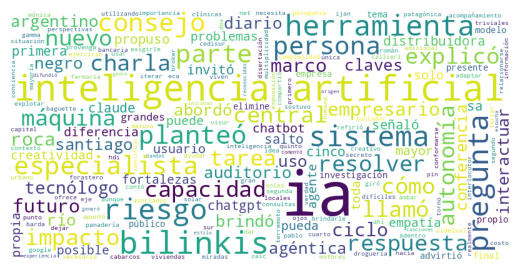

In [107]:
# Creo un objeto WordCloud con el texto filtrado
wordcloud_filtrado = WordCloud(width=800, height=400, background_color="white").generate(texto_filtrado)

# Muestro la explicación de la nube de palabras
display(HTML("""
<p style="font-size: 16px;">
<b>Segunda nube:</b> tamaño de la palabra = cantidad de apariciones.
</p>
<br />
"""))

# Muestro la imagen generada
plt.figure(figsize=(5, 5), facecolor=None)
plt.imshow(wordcloud_filtrado)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()

### 2.3 Usando el texto que conseguí en el punto 1:

#### 2.3.1 Limpio y preproceso el texto, lo descompongo en oraciones, armo una matriz documento-vocabulario.

In [66]:
# Descompongo el texto ORIGINAL en oraciones
oraciones = nltk.sent_tokenize(texto, language="spanish")

# Muestro la cantidad de oraciones
print("Cantidad de oraciones:", len(oraciones))
print()

# Muestro las primeras oraciones, una por línea
for oracion in oraciones[:3]:
    print(oracion)

Cantidad de oraciones: 40

En el marco del ciclo «Roca Futuro», el empresario y tecnólogo argentino Santiago Bilinkis brindó una conferencia sobre inteligencia artificial en el auditorio de Diario Río Negro, donde abordó las claves para interactuar con estas herramientas, el impacto de la «IA agéntica» y los riesgos asociados a su uso.
En el marco del ciclo de charlas «Roca Futuro», el empresario y tecnólogo argentino Santiago Bilinkis brindó una conferencia sobre Inteligencia Artificial (IA) en el auditorio de Diario Río Negro.
La disertación contó con el acompañamiento de empresas locales como IJAN, Pin Capital, La Baguette, Distribuidora Pablo SA, El Forastero, Cedisur, Distribuidora Gamma, Solar Urbano, HDI, Callieri, Barda Sur, Oldelval, Droguería Patagónica, ECA SA, Panadería Mónica, Farmacia Ámbar Bancaria, 365 Broker, Net Patagonia, Cabarcos Motores, 2 Soles, Clínicas de Ojos Román, Visur Viviendas y Caic.


In [67]:
# Creo una lista para guardar las oraciones procesadas
oraciones_procesadas = []

# Recorro todas las oraciones
for oracion in oraciones:
    # Convierto la oración a minúsculas
    oracion_minusculas = oracion.lower()

    # Quito los signos de puntuación
    oracion_sin_puntuacion = "".join(
        caracter for caracter in oracion_minusculas if caracter not in string.punctuation
    )

    # Quito los caracteres extraños
    oracion_limpia = quitar_emojis(oracion_sin_puntuacion)

    # Separo la oración en palabras
    palabras_oracion = oracion_limpia.split()

    # Quito las stop words
    palabras_oracion_filtradas = [
        palabra for palabra in palabras_oracion if palabra not in stopwords_es
    ]

    # Uno nuevamente las palabras y guardo la oración procesada
    oraciones_procesadas.append(" ".join(palabras_oracion_filtradas))

# Muestro la cantidad de oraciones
print("Cantidad de oraciones:", len(oraciones))
print()

# Muestro las primeras oraciones procesadas, una por línea
for oracion in oraciones_procesadas[:3]:
    print(oracion)

Cantidad de oraciones: 40

marco ciclo roca futuro empresario tecnólogo argentino santiago bilinkis brindó conferencia inteligencia artificial auditorio diario río negro abordó claves interactuar herramientas impacto ia agéntica riesgos asociados uso
marco ciclo charlas roca futuro empresario tecnólogo argentino santiago bilinkis brindó conferencia inteligencia artificial ia auditorio diario río negro
disertación contó acompañamiento empresas locales ijan pin capital baguette distribuidora pablo sa forastero cedisur distribuidora gamma solar urbano hdi callieri barda sur oldelval droguería patagónica eca sa panadería mónica farmacia ámbar bancaria 365 broker net patagonia cabarcos motores 2 soles clínicas ojos román visur viviendas caic


> Es exactamente todo lo que había hecho con el texto, solo que ahora lo hago con el texto original.
>
> Le hago el mismo preprocesamiento por oraciones, para no perder la separación.


#### 2.3.2 Determino la longitud de mi vocabulario.

In [82]:
# Creo el vectorizador
vectorizador = CountVectorizer()

# Creo la matriz documento-vocabulario a partir de las oraciones procesadas
matriz_documento_vocabulario = vectorizador.fit_transform(oraciones_procesadas)

# Obtengo las palabras que forman el vocabulario
vocabulario = vectorizador.get_feature_names_out()

# Obtengo la longitud del vocabulario
longitud_vocabulario = len(vocabulario)

# Muestro la longitud del vocabulario
print("Longitud del vocabulario:", longitud_vocabulario)

Longitud del vocabulario: 434


In [83]:
# Convierto la matriz en un DataFrame para visualizarla
tabla_documento_vocabulario = pd.DataFrame(
    matriz_documento_vocabulario.toarray(),
    columns=vocabulario,
    index=[f"Oración {i + 1}" for i in range(len(oraciones_procesadas))]
)

# Muestro la matriz documento-vocabulario
tabla_documento_vocabulario

,2025,2026,30,3000,365,50,80,abordó,acompañamiento,activación,...,visceral,visur,viven,viviendas,volúmenes,vos,vías,ámbar,última,única
Oración 1,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
Oración 2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Oración 3,0,0,0,0,1,0,0,0,1,0,...,0,1,0,1,0,0,0,1,0,0
Oración 4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Oración 5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Oración 36,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Oración 37,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Oración 38,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
Oración 39,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


#### 2.3.3 Aplico TF-IDF a mi matriz documento-vocabulario.

In [70]:
# Creo el vectorizador TF-IDF
vectorizador_tfidf = TfidfVectorizer()

# Ajusto el vectorizador a las oraciones procesadas
vectorizador_tfidf.fit(oraciones_procesadas)

# Obtengo la matriz TF-IDF
matriz_tfidf = vectorizador_tfidf.transform(oraciones_procesadas)

# Obtengo las palabras que forman el vocabulario
vocabulario_tfidf = vectorizador_tfidf.get_feature_names_out()

# Convierto la matriz en un DataFrame para visualizarla
tabla_tfidf = pd.DataFrame(
    matriz_tfidf.toarray(),
    columns=vocabulario_tfidf,
    index=[f"Oración {i + 1}" for i in range(len(oraciones_procesadas))]
)

# Configuro temporalmente la visualización de la tabla
with pd.option_context(
    "display.float_format", "{:.2f}".format,
    "display.max_rows", 10
):
    # Muestro la matriz TF-IDF
    display(tabla_tfidf)

,2025,2026,30,3000,365,50,80,abordó,acompañamiento,activación,...,visceral,visur,viven,viviendas,volúmenes,vos,vías,ámbar,última,única
Oración 1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.20,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Oración 2,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Oración 3,0.00,0.00,0.00,0.00,0.14,0.00,0.00,0.00,0.14,0.00,...,0.00,0.14,0.00,0.14,0.00,0.00,0.00,0.14,0.00,0.00
Oración 4,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Oración 5,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Oración 36,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Oración 37,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Oración 38,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.22,0.00
Oración 39,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [86]:
# Quiero mostrar la palabra más relevante de cada oración
resultados_relevantes = []

# Recorro cada oración de la matriz TF-IDF
for indice, fila in tabla_tfidf.iterrows():
    # Obtengo la palabra con mayor peso TF-IDF
    palabra_relevante = fila.idxmax()
    peso_tfidf_normalizado = fila.max()

    # Obtengo el número de la oración
    numero_oracion = int(indice.split()[-1]) - 1

    # Obtengo la posición de la palabra dentro de la oración
    palabras_oracion = oraciones_procesadas[numero_oracion].split()
    posicion = palabras_oracion.index(palabra_relevante) + 1

    # Obtengo la posición de la palabra dentro del vocabulario
    indice_vocabulario = vectorizador.vocabulary_[palabra_relevante]

    # Obtengo el TF desde la matriz documento-vocabulario
    tf = matriz_documento_vocabulario[
        numero_oracion,
        indice_vocabulario
    ]

    # Obtengo el IDF calculado por TfidfVectorizer
    idf = vectorizador_tfidf.idf_[
        vectorizador_tfidf.vocabulary_[palabra_relevante]
    ]

    # Calculo el TF-IDF antes de la normalización L2
    tf_idf = tf * idf

    # Guardo los resultados
    resultados_relevantes.append([
        indice,
        palabra_relevante,
        posicion,
        tf,
        idf,
        tf_idf,
        peso_tfidf_normalizado
    ])

# Creo una tabla con los resultados
tabla_relevantes = pd.DataFrame(
    resultados_relevantes,
    columns=[
        "Oración",
        "Palabra más relevante",
        "Posición dentro de la oración",
        "TF",
        "IDF",
        "TF × IDF",
        "TF-IDF normalizado L2"
    ]
)

# Aplico el estilo de la tabla
display(HTML(style_datatables))

# Muestro la tabla paginada ordenada por TF-IDF normalizado L2 de mayor a menor
data_table.DataTable(
    tabla_relevantes
        .sort_values(by="TF-IDF normalizado L2", ascending=False)
        .assign(
            IDF=lambda tabla: tabla["IDF"].map(
                lambda valor: f"{valor:.2f}"
            ),
            **{
                "TF × IDF": lambda tabla: tabla["TF × IDF"].map(
                    lambda valor: f"{valor:.2f}"
                ),
                "TF-IDF normalizado L2": lambda tabla: tabla[
                    "TF-IDF normalizado L2"
                ].map(
                    lambda valor: f"{valor:.2f}"
                )
            }
        ),
    include_index=False,
    num_rows_per_page=10,
    min_width="600px"
)

,Oración,Palabra más relevante,Posición dentro de la oración,TF,IDF,TF × IDF,TF-IDF normalizado L2
20,Oración 21,2025,3,2,3.61,7.23,0.63
18,Oración 19,definió,3,1,4.02,4.02,0.58
4,Oración 5,consejos,4,1,4.02,4.02,0.57
27,Oración 28,elimine,4,2,4.02,8.04,0.55
14,Oración 15,fortalezas,1,2,4.02,8.04,0.54
...,...,...,...,...,...,...,...
29,Oración 30,50,15,1,4.02,4.02,0.23
0,Oración 1,asociados,26,1,4.02,4.02,0.22
23,Oración 24,análisis,5,1,4.02,4.02,0.22
37,Oración 38,autónoma,8,1,4.02,4.02,0.22


> Al mirar estos resultados, hay dos ejemplos que me llaman la atención y quiero profundizar:
>
> * “2025” — peso alto: 0.63.
>   * Aparece varias veces dentro de una oración corta (TF alto)
>   * Aparece en pocas de las demás oraciones (IDF alto).
>   * La combinación de ambos factores (TF-IDF) hace que obtenga un peso elevado.
>
> * “asociados” — peso bajo: 0.22.
>   * Aparece una sola vez dentro de su oración (TF bajo).
>   * No aparece en las demás oraciones (IDF alto).
>   * Además, se encuentra en una oración larga con muchas otras palabras poco frecuentes. Al normalizar los valores, su peso (TF-IDF) resulta menor.
>
> Estos ejemplos muestran que un IDF alto no garantiza por sí solo un TF-IDF alto.
>
> **La normalización L2** lleva los valores TF-IDF a una misma escala, lo que permite comparar mejor la relevancia de las palabras entre distintas oraciones.

#### 2.3.4 Explico el formato de mi matriz resultante: documentos, vocabulario, tamaño. Brindo mis conclusiones.

In [97]:
# Obtengo la cantidad de documentos y palabras del vocabulario
cantidad_documentos = len(oraciones_procesadas)
cantidad_vocabulario = len(vocabulario)

# Obtengo el tamaño de la matriz TF-IDF
filas, columnas = matriz_tfidf.shape

# Muestro la explicación
display(HTML(f"""
<span style="font-size: 15px;">
La matriz resultante contiene <b>{cantidad_documentos} documentos</b>, correspondientes a las oraciones del texto.<br>
El vocabulario contiene <b>{cantidad_vocabulario} palabras únicas</b>.<br>
El tamaño de la matriz es de <b>{filas} × {columnas}</b>.<br>
Cada valor representa el peso TF-IDF de una palabra en una oración.<br>
Cuanto mayor es el peso, mayor es su relevancia dentro de esa oración respecto del resto del texto.
</span>
"""))

#### 2.3.5 Tercera nube de palabras.

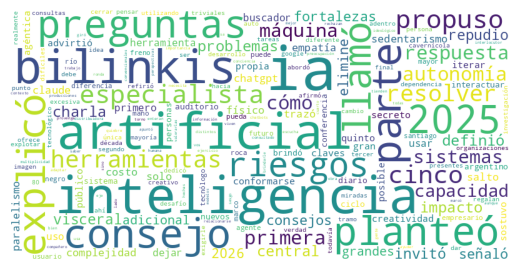

In [105]:
# Obtengo el peso TF-IDF total de cada palabra
pesos_tfidf = tabla_tfidf.sum(axis=0)

# Relaciono cada palabra del vocabulario con su peso TF-IDF total
frecuencias_tfidf = pesos_tfidf.to_dict()

# Creo un objeto WordCloud utilizando los pesos TF-IDF
wordcloud_tfidf = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate_from_frequencies(frecuencias_tfidf)

# Muestro la explicación de la nube de palabras
display(HTML("""
<p style="font-size: 16px;">
<b>Tercera nube:</b> tamaño de la palabra = suma de sus pesos TF-IDF en todas las oraciones.
</p>
<br />
"""))

# Muestro la nube de palabras
plt.figure(figsize=(5, 5), facecolor=None)
plt.imshow(wordcloud_tfidf)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()

# Conclusiones

Agregue aquí sus conclusiones sobre este trabajo práctico. Puede ser también parte del texto que posteará en el foro.

> En este trabajo práctico pude aplicar distintas técnicas de procesamiento de texto sobre una nota periodística obtenida mediante web scraping. A partir de la limpieza y el preprocesamiento, pude analizar las palabras más frecuentes, eliminar aquellas que no aportaban información relevante y representar los resultados mediante tablas y nubes de palabras. También pude ver que frecuencia y relevancia no significan necesariamente lo mismo.

> Al dividir el texto en oraciones y construir la matriz documento-vocabulario, pude transformar el contenido en una representación numérica. Luego, con TF-IDF, pude analizar la relevancia de cada palabra teniendo en cuenta tanto su frecuencia dentro de una oración (TF) como su aparición en las demás oraciones (IDF). Esto me permitió entender mejor cómo se puede representar un texto de una forma que después pueda ser utilizada para otros tipos de análisis.

> Algo que me resultó especialmente interesante fue comparar los resultados. Por ejemplo, “2025” obtiene un peso alto porque aparece varias veces en una oración corta y en pocas de las demás oraciones, mientras que “asociados”, aunque es una palabra poco frecuente, obtiene un peso menor porque aparece una sola vez dentro de una oración más larga, donde hay otras palabras relevantes entre las que el peso se distribuye de manera más equilibrada.

> También me pareció interesante comparar las nubes de palabras: unas basadas en frecuencia y otra en los pesos TF-IDF, ya que permiten visualizar dos formas diferentes de analizar la importancia de las palabras.

# Anexo, código de ejemplo del uso de wordcloud

Texto de ejemplo

In [73]:
# Texto de ejemplo
text = "Este es un texto de ejemplo para crear una nube de palabras usando word cloud. Puedes reemplazar este texto utilizando tu propio texto."

# Crear un objeto WordCloud
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)

Mostramos la imagen generada

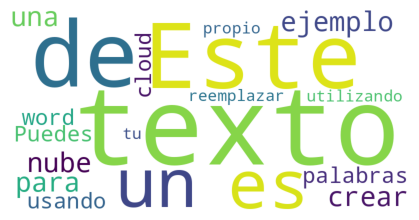

In [74]:
# mostramos la imagen generada
plt.figure(figsize=(4, 4), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()